# Inference-resolution ablation (DPT §4.3)

Models: B and AB1 (frame-consistent PE) on Cityscapes, B on NYUv2. The input (Cityscapes 512×1024, NYUv2 480×640) is resized by s ∈ {0.5, 0.75, 0.875, 1.0, 1.25, 1.5}. The prediction is resized back to the evaluation resolution of the standard protocol:
- Cityscapes depth: 512×1024 (SwinMTL Tab. I);
- Cityscapes mIoU: 1024×2048, 19 classes;
- NYUv2: 480×640, Eigen crop.

Resizing the whole image keeps the field of view, so the metric depth stays valid. I report AbsRel, RMSE, the mean log bias (prediction / GT) and mIoU. s = 1 is the standard single-pass result. On Cityscapes, s = 0.875 corresponds to the 448-pixel height of the training crops (448 / 512); on NYUv2 the crop is almost the full frame (476 / 480 ≈ 0.99).

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [ ]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
from mtl_common import *

configure()
SCALES = [0.5, 0.75, 0.875, 1.0, 1.25, 1.5]
OUT_DIR = ROOT / "results" / "compare"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Device: {device}")


Device: cuda


## 1. Evaluation at several input resolutions

In [3]:
@torch.no_grad()
def eval_resolution(model: nn.Module, dataset: str, s: float) -> dict:
    """Single pass with the input resized by s; metrics at the standard evaluation resolution."""
    dcfg = CFG["datasets"][dataset]
    ds = make_dataset(dataset, dcfg["eval_split"], train=False)
    n = len(ds)
    depth_meter = DepthMeter(dcfg["min_depth"], dcfg["max_depth"])
    seg_meter = SegMeter(dcfg["eval_classes"])
    biases = []
    model.eval()
    for i in tqdm(range(n), desc=f"{dataset} s={s}", leave=False):
        sample = ds[i]
        img = sample["image"][None].to(device)
        gt_depth = sample["depth"].to(device)
        gt_depth = gt_depth[0] if gt_depth.ndim == 3 else gt_depth
        gt_seg = sample["seg"].to(device)
        h, w = img.shape[-2:]
        x = img if s == 1.0 else F.interpolate(img, size=(int(round(h * s)), int(round(w * s))), mode="bilinear", align_corners=False)
        depth, probs = predict(model, x)
        if dataset == "cityscapes":
            depth = F.interpolate(depth, size=(h, w), mode="bilinear", align_corners=False)[0, 0]      # 512x1024
            gt_eval = F.interpolate(gt_depth[None, None], size=(h, w), mode="nearest")[0, 0]
            mask = None
            valid = (gt_eval > dcfg["min_depth"]) & (gt_eval < dcfg["max_depth"])
            H, W = gt_seg.shape
            pred_seg = F.interpolate(probs, size=(H, W), mode="bilinear", align_corners=False)[0][:dcfg["eval_classes"]].argmax(0)
            seg_meter.update(pred_seg, cs_to_eval(gt_seg))
        else:
            H, W = gt_depth.shape
            depth = F.interpolate(depth, size=(H, W), mode="bilinear", align_corners=False)[0, 0]
            gt_eval = gt_depth
            mask = eigen_crop_mask(H, W)
            valid = (gt_eval > dcfg["min_depth"]) & (gt_eval < dcfg["max_depth"]) & mask
            pred_seg = F.interpolate(probs, size=(H, W), mode="bilinear", align_corners=False)[0].argmax(0)
            seg_meter.update(pred_seg, gt_seg)
        if mask is None:
            depth_meter.update(depth, gt_eval)
        else:
            depth_meter.update(depth, gt_eval, mask)
        pred = depth.clamp(dcfg["min_depth"], dcfg["max_depth"])
        biases.append((torch.log(pred[valid]) - torch.log(gt_eval[valid])).mean().item())
    d = depth_meter.result()
    return {"abs_rel": d["abs_rel"], "rmse": d["rmse"], "d1": d["d1"], "log_bias": float(np.mean(biases)), "mIoU": seg_meter.result()["mIoU"]}


MODELS = [
    ("cityscapes", "B", dict()),
    ("cityscapes", "AB1 (frame-consistent PE)", dict(frame_pe=True, ckpt_root=ROOT / "ckpt" / "fpe", results_root=ROOT / "results" / "fpe")),
    ("nyu", "B", dict()),
]
rows = []
for dataset, label, overrides in MODELS:
    configure(**overrides)
    model = load_trained(dataset, "partial_ft")
    for s in SCALES:
        r = eval_resolution(model, dataset, s)
        rows.append(dict(dataset=dataset, model=label, scale=s, **r))
        print(dataset, label, s, {k: round(v, 4) for k, v in r.items()})
    del model
    torch.cuda.empty_cache()
configure()

res_table = pd.DataFrame(rows)
res_table.to_csv(OUT_DIR / "ablation_inference_resolution.csv", index=False)
display(res_table.set_index(["dataset", "model", "scale"]).style.format(precision=4))



cityscapes s=0.5:   0%|          | 0/500 [00:00<?, ?it/s]

cityscapes B 0.5 {'abs_rel': 0.5084, 'rmse': 13.1437, 'd1': 0.1121, 'log_bias': 0.3907, 'mIoU': 68.0028}



cityscapes s=0.75:   0%|          | 0/500 [00:00<?, ?it/s]

cityscapes B 0.75 {'abs_rel': 0.2562, 'rmse': 7.921, 'd1': 0.6192, 'log_bias': 0.2055, 'mIoU': 74.4138}



cityscapes s=0.875:   0%|          | 0/500 [00:00<?, ?it/s]

cityscapes B 0.875 {'abs_rel': 0.1726, 'rmse': 6.2721, 'd1': 0.8415, 'log_bias': 0.1316, 'mIoU': 76.6402}


... (32 outputs left out)


nyu s=1.25:   0%|          | 0/654 [00:00<?, ?it/s]

nyu B 1.25 {'abs_rel': 0.1318, 'rmse': 0.4972, 'd1': 0.8154, 'log_bias': -0.0751, 'mIoU': 57.053}



nyu s=1.5:   0%|          | 0/654 [00:00<?, ?it/s]

nyu B 1.5 {'abs_rel': 0.164, 'rmse': 0.6079, 'd1': 0.6878, 'log_bias': -0.1444, 'mIoU': 57.676}


### Plot

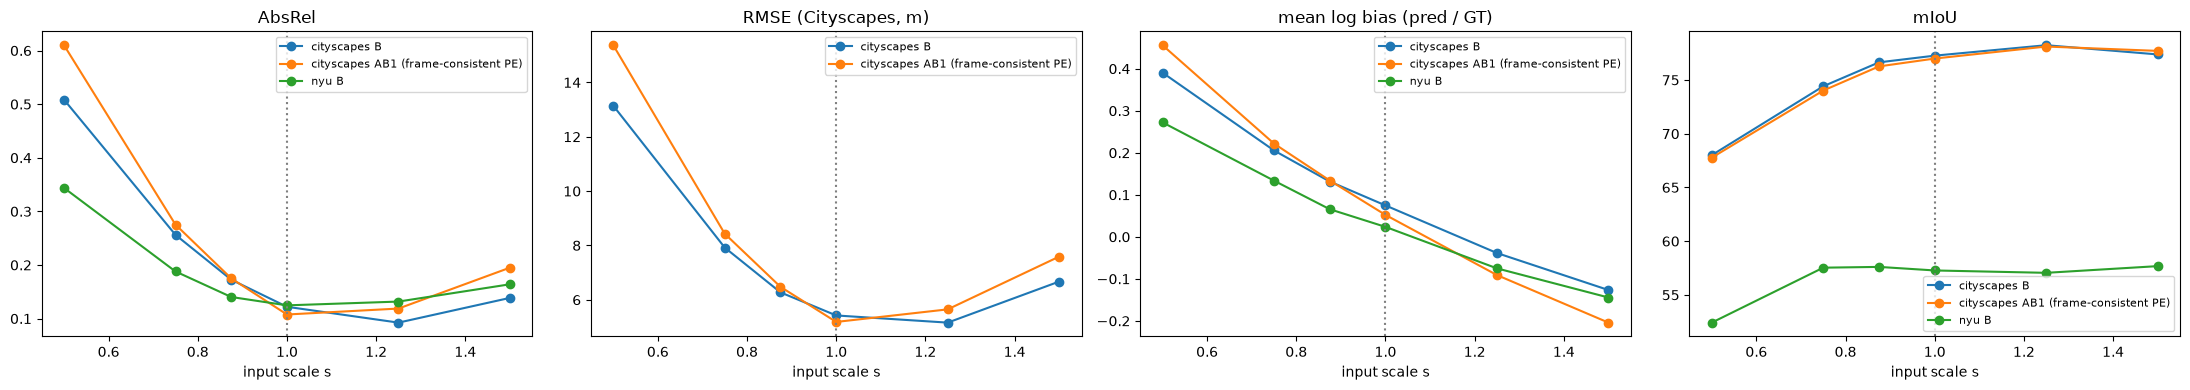

In [4]:
fig, axs = plt.subplots(1, 4)
fig.set_size_inches(22, 4)
for (dataset, label), group in res_table.groupby(["dataset", "model"], sort=False):
    for ax, col in zip(axs, ["abs_rel", "rmse", "log_bias", "mIoU"]):
        if col == "rmse" and dataset == "nyu":
            continue   # different scale (m); NYU RMSE is in the table
        ax.plot(group["scale"], group[col], "o-", label=f"{dataset} {label}")
for ax, title in zip(axs, ["AbsRel", "RMSE (Cityscapes, m)", "mean log bias (pred / GT)", "mIoU"]):
    ax.axvline(1.0, color="gray", ls=":")
    ax.set_title(title)
    ax.set_xlabel("input scale s")
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT_DIR / "ablation_inference_resolution.png", dpi=120)
plt.show()
